Code for A bspline curve s(x) that maps from parameteric space $x \in R$ to $s \in R$:\

$s(x)=\sum_i P_i N_{i,p}(x)$




In [35]:
import torch
import matplotlib.pyplot as plt
import numpy as np

x = torch.linspace(0,0.99,1000)


class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        # Clamped knot vector is for interpolatory ends
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        self.nodal_values = torch.rand(n_basis)

    def forward(self,x):

        def bspline_basis(i, p, x, knots):
            if p == 0:
                return ((x >= knots[i]) & (x < knots[i+1])).float()
            else:
                denom1 = knots[i+p] - knots[i]
                denom2 = knots[i+p+1] - knots[i+1]

                term1 = 0.0
                if denom1 > 0:
                    term1 = (x - knots[i]) / denom1 * bspline_basis(i, p-1, x, knots)

                term2 = 0.0
                if denom2 > 0:
                    term2 = (knots[i+p+1] - x) / denom2 * bspline_basis(i+1, p-1, x, knots)

                return term1 + term2
        
        y = torch.zeros(self.n_basis, x.shape[0])
        for i in range(self.n_basis):
            y[i] = bspline_basis(i, self.degree, x, self.knot_vector)
                
        bspline = self.nodal_values@y

        return bspline


In [39]:
torch.manual_seed(42)
model = bsplines(5,2)

In [42]:
model.knot_vector

tensor([0.0000, 0.0000, 0.0000, 0.3333, 0.6667, 1.0000, 1.0000, 1.0000])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


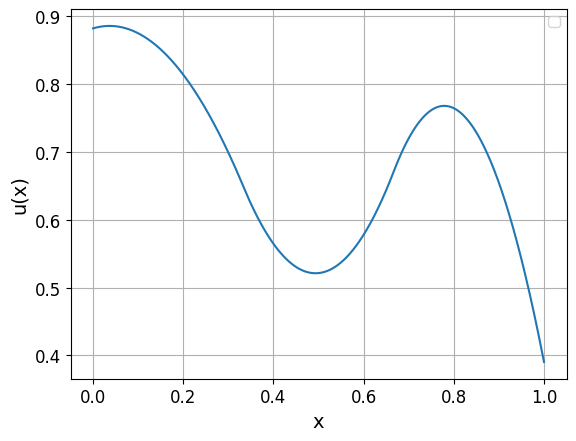

In [40]:
x = torch.linspace(0,0.99999,1000)
y_pred = model.forward(x)

plt.plot(x,y_pred)
# plt.plot(x.detach().numpy(), -(x.detach().numpy()**2)/2+1/2*x.detach().numpy(), label="exact u(x)")
# plt.plot(x.detach().numpy(),y_pred_sp,':', label="splines")
plt.legend()
# plt.yscale('log')
# plt.title("Losses",fontsize=14)
plt.xlabel("x",fontsize=14)
plt.ylabel("u(x)",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)

# plt.savefig("FEM_splines.pdf", dpi=300)
plt.show()

APPly here the cox de Boor algorithm snd check if it is the same reuslt as the above implementation:\
For example check if model.forward(0.5) is the same number as the cox de Boor algorithm with input 0.5